In [1]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm
import h5py

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

import sys
sys.path.append("..") 

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [2]:
from processing import  load_UCI_dataset, plot_regression_results, print_metrics, plot_convtran_loss
from UCI.pre_processing import  create_dataloaders

In [3]:
BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/8sec_0overlap/vitaldb_checkpoints"
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(WINDOW_SIZE= 1000, STEP_SIZE= 1000)

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [01:21<00:00, 118.16it/s]


Skipped recordings: 107


100%|██████████| 1200/1200 [00:10<00:00, 112.60it/s]


Skipped recordings: 8


100%|██████████| 1200/1200 [00:10<00:00, 112.85it/s]


Skipped recordings: 9


In [4]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# The shape should be : (batch, channels, length), length = 8*125 = 1000samples, only one channel as PPG and 

X_train: (263103, 1, 1000)
y_train: (263103, 2)
X_val: (33223, 1, 1000)
y_val: (33223, 2)
X_test: (33347, 1, 1000)
y_test: (33347, 2)


In [5]:
print(X_train.dtype)
print(y_train.dtype)


float32
float32


In [6]:
cat ConvTran/Models/model.py

import numpy as np
from torch import nn
from Models.AbsolutePositionalEncoding import tAPE, AbsolutePositionalEncoding, LearnablePositionalEncoding
from Models.Attention import Attention, Attention_Rel_Scl, Attention_Rel_Vec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class Permute(nn.Module):
    def forward(self, x):
        return x.permute(1, 0, 2)


def model_factory(config):
    if config['Net_Type'][0] == 'T':
        model = Transformer(config, output_size=config['output_size'])
    elif config['Net_Type'][0] == 'CC-T':
        model = CasualConvTran(config, output_size=config['output_size'])
    else:
        model = ConvTran(config, output_size=config['output_size'])
    return model


class Transformer(nn.Module):
    def __init__(self, config, output_size):
        super().__init__()
        # Parameters Initialization -----------------------------------------------
        channel_size, seq_len = config['Data_sh

In [7]:
train_loader, val_loader, test_loader = create_dataloaders(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    batch_size=64
)

X_batch, y_batch = next(iter(train_loader))

print("X:", X_batch.shape, X_batch.dtype)
print("y:", y_batch.shape, y_batch.dtype)

X: torch.Size([64, 1, 1000]) torch.float32
y: torch.Size([64, 2]) torch.float32


In [8]:
config = {
    # Input
    'Data_shape': (32, 1, 1000),

    # ConvTran architecture
    'emb_size': 16,
    'num_heads': 8,
    'dim_ff': 256,

    # Positional encoding
    'Fix_pos_encode': 'tAPE',
    'Rel_pos_encode': 'eRPE',

    # Dropout
    'dropout': 0.01,

    # Regression
    'output_size': 2,

    # Model type
    'Net_Type': ['C-T'],
}

In [9]:
import sys

sys.path.insert(
    0,
    "/data1/yashvi_bhuva/BP_estimation_using_PPG/ConvTran/ConvTran"
)
from Models.model import model_factory
model = model_factory(config)

X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("Input :", X_batch.shape)
print("Output:", output.shape)

Input : torch.Size([64, 1, 1000])
Output: torch.Size([64, 2])


In [10]:
import torch.nn as nn

criterion = nn.SmoothL1Loss()

loss = criterion(output, y_batch)

print("Prediction shape:", output.shape)
print("Target shape:", y_batch.shape)
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful")

Prediction shape: torch.Size([64, 2])
Target shape: torch.Size([64, 2])
Loss: 96.2413330078125
Backward pass successful


In [11]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.step()

print("Optimizer step successful")

Optimizer step successful


In [12]:
model.train()

X_batch, y_batch = next(iter(train_loader))

optimizer.zero_grad()

pred = model(X_batch)

loss = criterion(pred, y_batch)

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("Training step successful")

Loss: 95.20112609863281
Training step successful


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_factory(config).to(device)

In [14]:
loss_module = torch.nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [15]:
from Training import SupervisedTrainer, validate, train_runner
trainer = SupervisedTrainer(
    model=model,
    dataloader=train_loader,
    device=device,
    loss_module=loss_module,
    optimizer=optimizer,
    l2_reg=None
)

val_evaluator = SupervisedTrainer(
    model=model,
    dataloader=val_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None
)

In [16]:
import os

config['optimizer'] = optimizer
config['loss_module'] = loss_module
config['patience'] = 5
config['key_metric'] = 'loss'
config['save_dir'] = './checkpoints'

os.makedirs(config['save_dir'], exist_ok=True)

In [17]:
config['epochs'] = 50

history = train_runner(
    config=config,
    model=model,
    trainer=trainer,
    val_evaluator=val_evaluator,
    path='./checkpoints/best_model.pth'
)

Training Epoch:   0%|          | 0/50 [00:00<?, ?it/s]2026-10-11 22:01:09,059 | INFO : Validation Summary: epoch: 1.000000 | loss: 81.347678 | SBP_MAE: 114.304436 | DBP_MAE: 49.390923 | SBP_RMSE: 116.502487 | DBP_RMSE: 50.624340 | 
2026-10-11 22:01:09,260 | INFO : Epoch 1 Training Summary: epoch: 1.000000 | loss: 89.513834 | SBP_MAE: 122.392464 | DBP_MAE: 57.635227 | SBP_RMSE: 124.432114 | DBP_RMSE: 58.855225 | 



Best validation loss: 81.34767821249689
Saving best model for epoch: 1



Training Epoch:   2%|▏         | 1/50 [19:37<16:01:15, 1177.04s/it]2026-10-11 22:19:18,142 | INFO : Validation Summary: epoch: 2.000000 | loss: 55.414044 | SBP_MAE: 89.006645 | DBP_MAE: 22.821447 | SBP_RMSE: 91.812355 | DBP_RMSE: 25.380638 | 
2026-10-11 22:19:18,340 | INFO : Epoch 2 Training Summary: epoch: 2.000000 | loss: 68.823679 | SBP_MAE: 102.520386 | DBP_MAE: 36.126968 | SBP_RMSE: 105.117157 | DBP_RMSE: 38.504776 | 
Training Epoch:   4%|▍         | 2/50 [37:46<15:00:14, 1125.30s/it]


Best validation loss: 55.41404423152353
Saving best model for epoch: 2



2026-10-11 22:28:52,376 | INFO : Validation Summary: epoch: 3.000000 | loss: 29.980778 | SBP_MAE: 52.473976 | DBP_MAE: 8.475431 | SBP_RMSE: 57.101215 | DBP_RMSE: 11.074642 | 
2026-10-11 22:28:52,567 | INFO : Epoch 3 Training Summary: epoch: 3.000000 | loss: 40.800746 | SBP_MAE: 71.311165 | DBP_MAE: 11.279947 | SBP_RMSE: 75.406105 | DBP_RMSE: 15.094030 | 
Training Epoch:   6%|▌         | 3/50 [47:20<11:24:22, 873.67s/it] 

...

2026-10-12 03:29:44,638 | INFO : Epoch 42 Training Summary: epoch: 42.000000 | loss: 8.611688 | SBP_MAE: 12.065990 | DBP_MAE: 6.123761 | SBP_RMSE: 16.457041 | DBP_RMSE: 8.934724 | 
Training Epoch:  84%|████████▍ | 42/50 [5:48:12<1:00:46, 455.77s/it]2026-10-12 03:37:17,969 | INFO : Validation Summary: epoch: 43.000000 | loss: 9.524775 | SBP_MAE: 13.234679 | DBP_MAE: 6.785362 | SBP_RMSE: 17.600307 | DBP_RMSE: 9.476899 | 
2026-10-12 03:37:17,973 | INFO : Epoch 43 Training Summary: epoch: 43.000000 | loss: 8.591399 | SBP_MAE: 12.040735 | DBP_MAE: 6.108273 | SBP_RMSE: 16.429335 | DBP_RMSE: 8.911730 | 
Training Epoch:  86%|████████▌ | 43/50 [5:55:45<53:05, 455.04s/it]  

2026-10-12 03:44:51,431 | INFO : Validation Summary: epoch: 44.000000 | loss: 9.512558 | SBP_MAE: 13.333558 | DBP_MAE: 6.661763 | SBP_RMSE: 17.703287 | DBP_RMSE: 9.349537 | 
2026-10-12 03:44:51,434 | INFO : Epoch 44 Training Summary: epoch: 44.000000 | loss: 8.569056 | SBP_MAE: 12.010262 | DBP_MAE: 6.093508 | SBP_RMSE: 16.403826 | DBP_RMSE: 8.903822 | 
Training Epoch:  88%|████████▊ | 44/50 [6:03:19<45:27, 454.56s/it]

2026-10-12 03:52:24,835 | INFO : Validation Summary: epoch: 45.000000 | loss: 9.535025 | SBP_MAE: 13.326343 | DBP_MAE: 6.715950 | SBP_RMSE: 17.603571 | DBP_RMSE: 9.402299 | 
2026-10-12 03:52:24,838 | INFO : Epoch 45 Training Summary: epoch: 45.000000 | loss: 8.542570 | SBP_MAE: 11.972612 | DBP_MAE: 6.078413 | SBP_RMSE: 16.366388 | DBP_RMSE: 8.882167 | 
Training Epoch:  90%|█████████ | 45/50 [6:10:52<37:51, 454.22s/it]

2026-10-12 03:59:58,090 | INFO : Validation Summary: epoch: 46.000000 | loss: 10.033465 | SBP_MAE: 13.999447 | DBP_MAE: 7.043005 | SBP_RMSE: 18.212879 | DBP_RMSE: 9.409670 | 
2026-10-12 03:59:58,094 | INFO : Epoch 46 Training Summary: epoch: 46.000000 | loss: 8.524360 | SBP_MAE: 11.948808 | DBP_MAE: 6.066187 | SBP_RMSE: 16.335329 | DBP_RMSE: 8.864779 | 
Training Epoch:  92%|█████████▏| 46/50 [6:18:25<30:15, 453.93s/it]

2026-10-12 04:07:31,383 | INFO : Validation Summary: epoch: 47.000000 | loss: 9.783194 | SBP_MAE: 13.796675 | DBP_MAE: 6.739985 | SBP_RMSE: 18.079336 | DBP_RMSE: 9.358638 | 
2026-10-12 04:07:31,387 | INFO : Epoch 47 Training Summary: epoch: 47.000000 | loss: 8.502923 | SBP_MAE: 11.921603 | DBP_MAE: 6.050033 | SBP_RMSE: 16.309847 | DBP_RMSE: 8.853593 | 
2026-10-12 04:07:31,387 | INFO : Early stopping at epoch 47. Best validation loss: 9.460271
2026-10-12 04:07:31,390 | INFO : Train Time: 6.0 hours, 25.0 minutes, 59.17480444908142 seconds



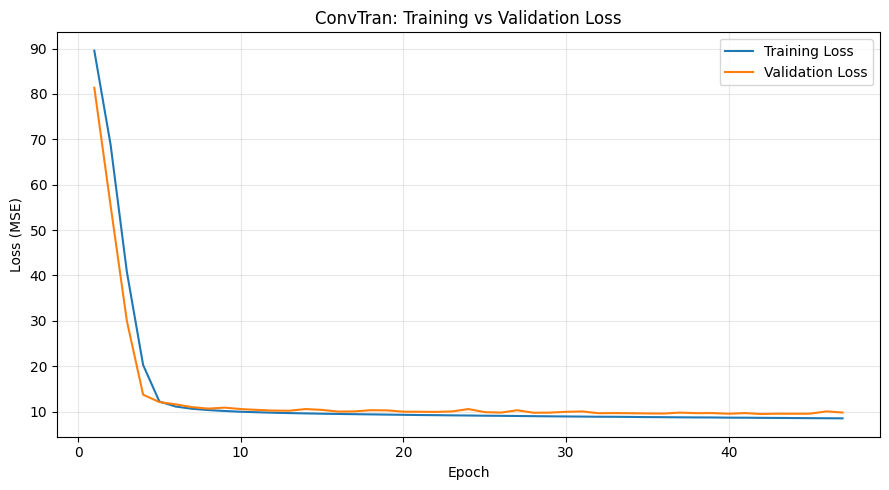

In [18]:
plot_convtran_loss(history)

In [19]:
checkpoint = torch.load(
    './checkpoints/model_best.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)

test_evaluator = SupervisedTrainer(
    model=model,
    dataloader=test_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None,
    print_interval=10,
    console=True,
    print_conf_mat=False
)

In [20]:
test_metrics, test_results = test_evaluator.evaluate(
    epoch_num=None,
    keep_all=True
)

In [21]:
y_true = test_results['targets']
y_pred = test_results['predictions']

print("True shape:", y_true.shape)
print("Pred shape:", y_pred.shape)

True shape: (33347, 2)
Pred shape: (33347, 2)


===== SBP Metrics =====
RMSE: 18.0925
MSE : 327.3390
R²  : 0.3802
MAE : 13.3608


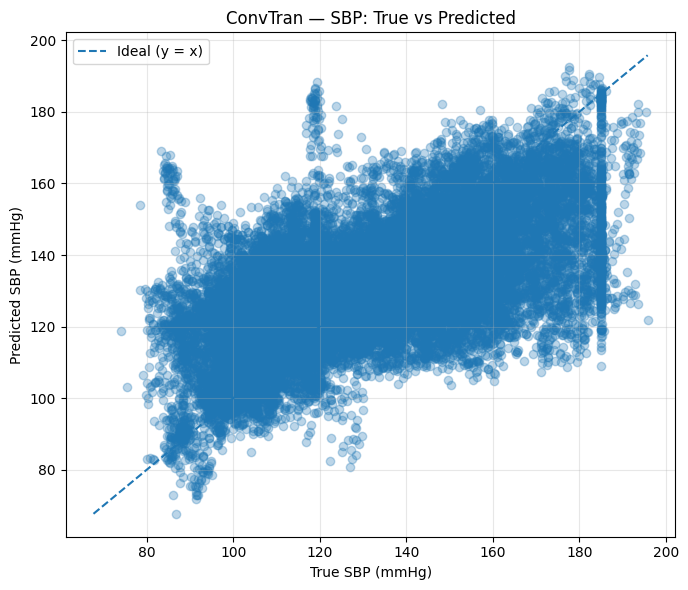

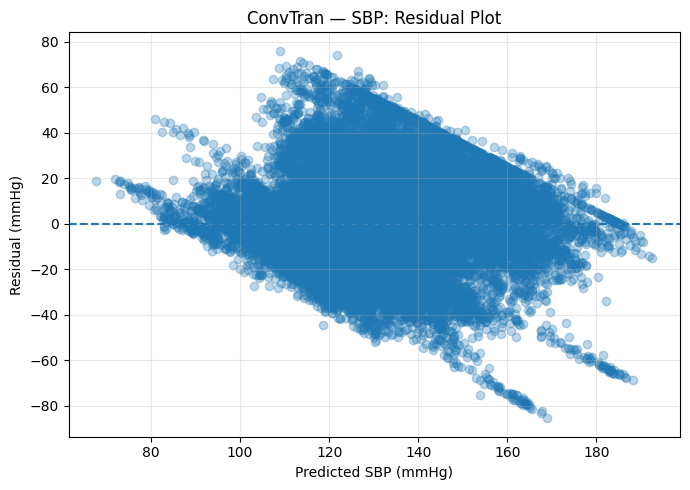

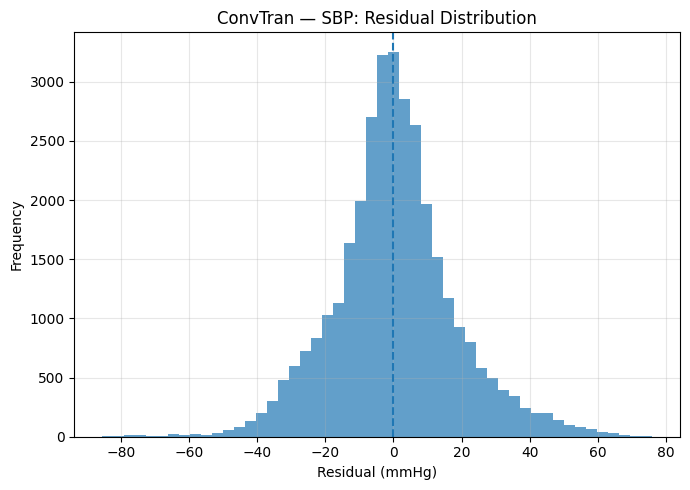

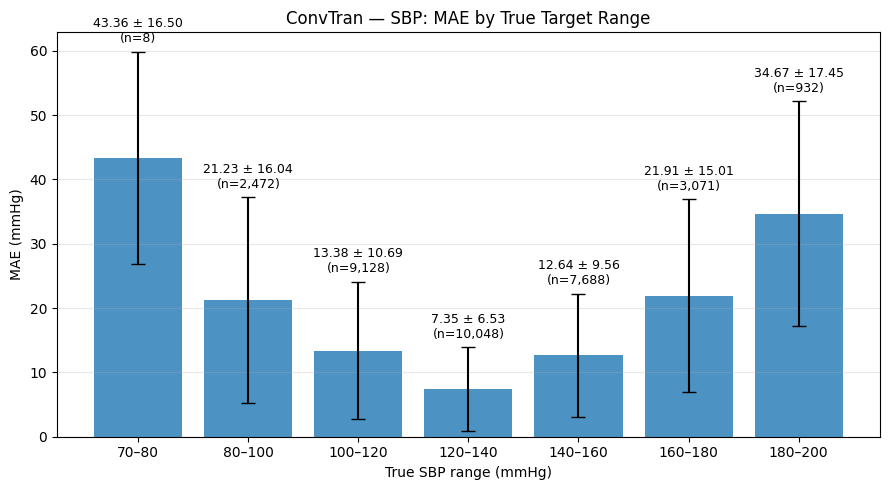

===== DBP Metrics =====
RMSE: 9.3295
MSE : 87.0399
R²  : 0.3032
MAE : 6.7849


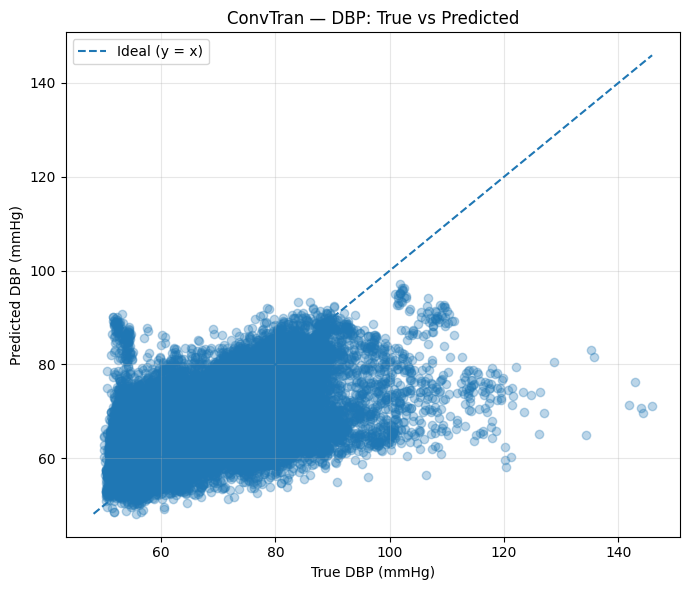

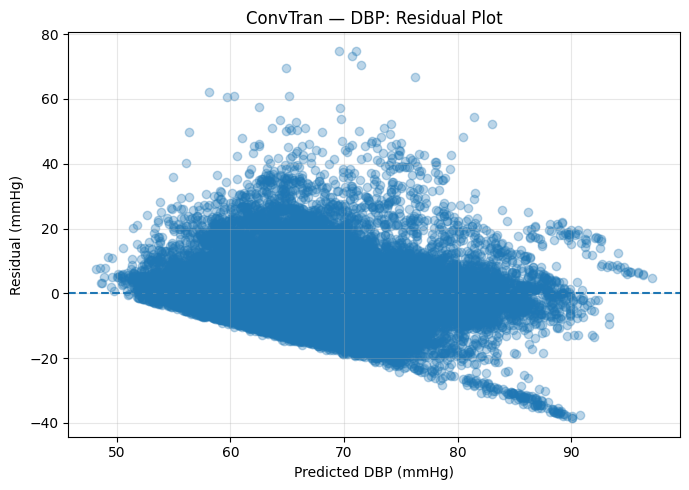

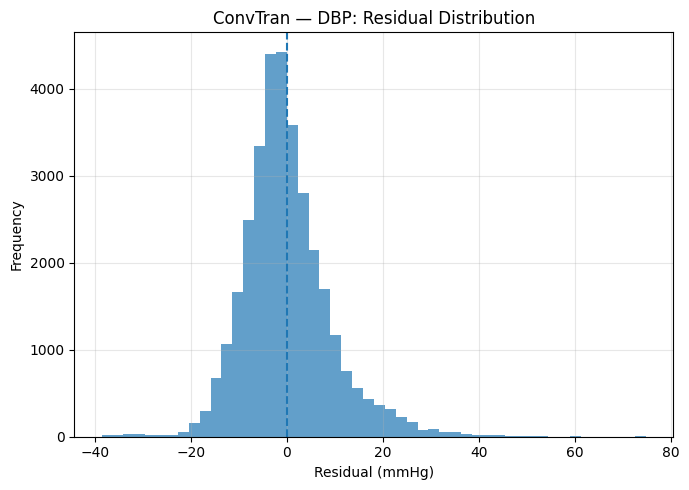

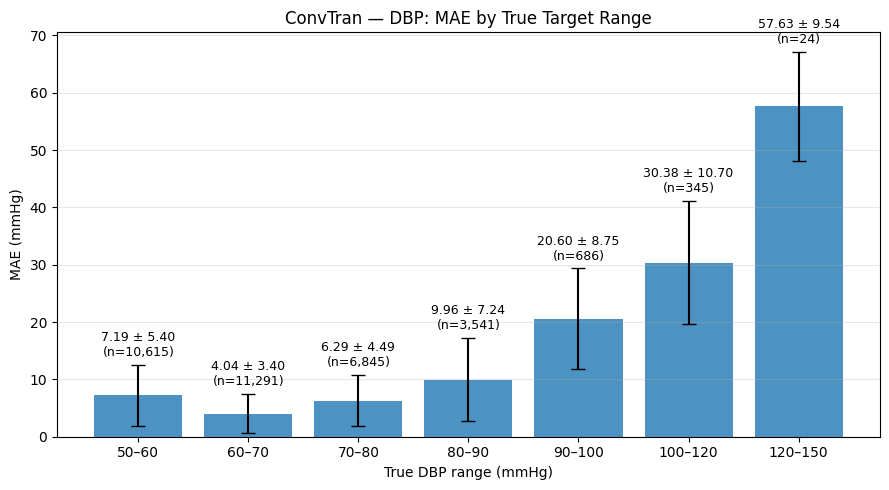

In [22]:
# Convert to NumPy arrays if they are PyTorch tensors
if torch.is_tensor(y_true):
    y_true = y_true.detach().cpu().numpy()

if torch.is_tensor(y_pred):
    y_pred = y_pred.detach().cpu().numpy()

# Extract SBP and DBP separately
sbp_true = y_true[:, 0]
sbp_pred = y_pred[:, 0]

dbp_true = y_true[:, 1]
dbp_pred = y_pred[:, 1]

# SBP metrics and plots
print("===== SBP Metrics =====")
print_metrics(sbp_true, sbp_pred)

plot_regression_results(
    sbp_true,
    sbp_pred,
    model_name="ConvTran",
    target_name="SBP"
)

# DBP metrics and plots
print("===== DBP Metrics =====")
print_metrics(dbp_true, dbp_pred)

plot_regression_results(
    dbp_true,
    dbp_pred,
    model_name="ConvTran",
    target_name="DBP"
)

In [ ]:
from processing import evaluate_convtran_vitaldb
convtran_vitaldb_results = evaluate_convtran_vitaldb(
    model=model,  # Your trained, best-checkpoint ConvTran model
    base_dir=BASE_DIR,
    batch_size=64,
    device=device
)

Number of VitalDB cases: 1968


ConvTran VitalDB prediction:  52%|█████▏    | 1033/1968 [21:33<20:36,  1.32s/case] 